# Walmart Sales Analysis

## Dataset Overview

- **File:** walmart.csv (walmart sales data)
- **Size:** 6435 orders and 8 columns
- **Objective:** clean the walmart sales data, perform EDA, identify sales trends and customer patterns, find outlers and investigate them, and present findings with charts and recommendations.

In [ ]:
import pandas as pd
df = pd.read_csv('../data/walmart.csv')

In [ ]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


In [ ]:
df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


In [ ]:
# missing values
print(df.isnull().sum())

# duplicates
print(df.duplicated().sum())
print(df.duplicated(subset=['Store', 'Date']).sum())

# validation
print(df['Holiday_Flag'].unique())
print("Zero or negative sales:", (df["Weekly_Sales"] <= 0).sum())

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64
0
0
[0 1]
Zero or negative sales: 0


In [ ]:
#this changes all the col headings into snake_case and date into datetime datatype.
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
df.columns = df.columns.str.lower()
df.columns

Index(['store', 'date', 'weekly_sales', 'holiday_flag', 'temperature',
       'fuel_price', 'cpi', 'unemployment'],
      dtype='object')

In [ ]:
df.head()

,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [ ]:
cols = ['weekly_sales', 'temperature', 'fuel_price', 'cpi', 'unemployment']

for c in cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n = ((df[c] < low) | (df[c] > high)).sum()
    print(c, '| outliers:', n, '| low:', round(low, 2), '| high:', round(high, 2))

weekly_sales | outliers: 34 | low: -746862.73 | high: 2720371.49
temperature | outliers: 3 | low: 6.24 | high: 116.16
fuel_price | outliers: 0 | low: 1.73 | high: 4.94
cpi | outliers: 0 | low: 10.22 | high: 334.26
unemployment | outliers: 481 | low: 4.29 | high: 11.22


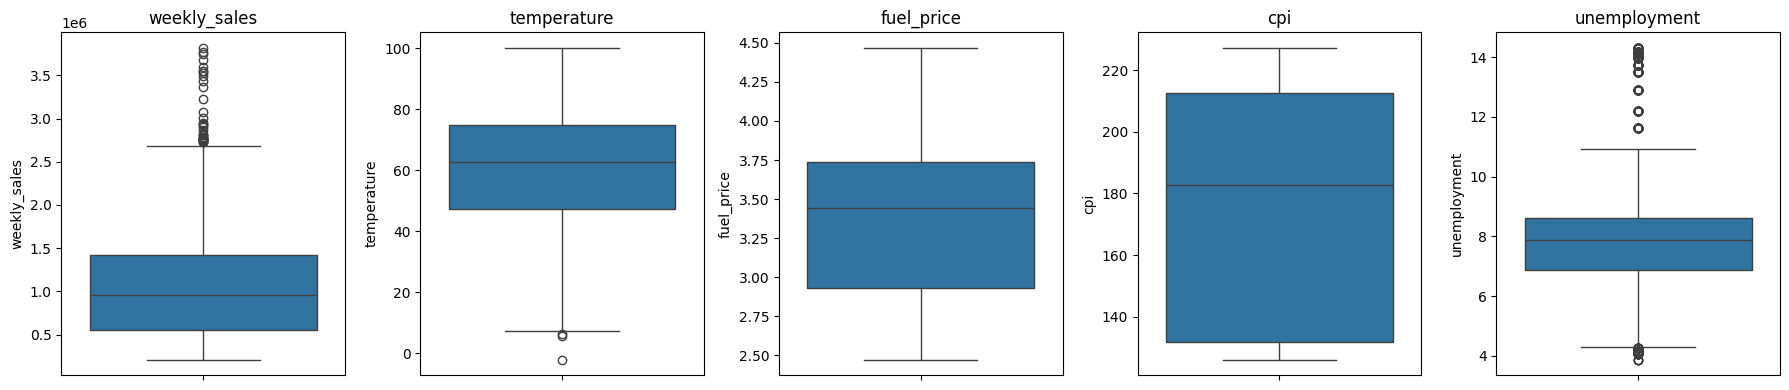

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

In [ ]:
#investigate the outliers..and decice weather to remove it or not.
out = df[df['weekly_sales'] > 2720371.49]

#in which months did these high sales happen?
print(out['date'].dt.month.value_counts())

#were these weeks marked as holiday weeks?
print(out['holiday_flag'].value_counts())

#stores with unemployment more then 11.22%, this could cause low sales
#compare to the other region because people are more umemployed..
high = df[df['unemployment'] > 11.22]
low = df[df['unemployment'] < 4.29]
print('high:', len(high), high['store'].unique())
print('low:', len(low), low['store'].unique())

date
12    25
11     9
Name: count, dtype: int64
holiday_flag
0    25
1     9
Name: count, dtype: int64
high: 378 [12 28 38]
low: 103 [ 4 23 40]


In [ ]:
#these are all the outliers
out.head()

,store,date,weekly_sales,holiday_flag,temperature,fuel_price,cpi,unemployment
189,2,2010-12-24,3436007.68,0,49.97,2.886,211.064660,8.163
241,2,2011-12-23,3224369.80,0,46.66,3.112,218.999550,7.441
471,4,2010-11-26,2789469.45,1,48.08,2.752,126.669267,7.127
474,4,2010-12-17,2740057.14,0,46.57,2.884,126.879484,7.127
475,4,2010-12-24,3526713.39,0,43.21,2.887,126.983581,7.127


In [ ]:
#Saving the walmart_cleaned.
df.to_csv('walmart_cleaned.csv', index=False)

# Data Cleaning Summary

## Before vs After Comparison

| Metric | Before | After |
|---|---|---|
| Rows | 6,435 | 6,435 |
| Columns | 8 | 8 (51 in the encoded copy) |
| Missing values | 0 | 0 |
| Duplicate rows | 0 | 0 |
| Duplicate store + date pairs | 0 | 0 |
| `date` type | object (text) | datetime64 |
| Column names | Mixed case (e.g. `Weekly_Sales`) | snake_case (e.g. `weekly_sales`) |
| `weekly_sales` outliers | 34 | 34 (kept) |
| `temperature` outliers | 3 | 3 (kept) |
| `unemployment` outliers | 481 | 481 (kept) |

## Cleaning Steps and Decisions

1. **Missing values and duplicates:** I checked every column and found no missing values, no duplicate rows and no duplicate store and date pairs, so no rows were removed.

2. **Column names:** I changed all column names to lowercase snake_case, for example `Weekly_Sales` became `weekly_sales`, to keep them consistent.

3. **Data types:** The `date` column was text, so I converted it to a real date (day-month-year format, using `dayfirst=True`). All other columns already had the correct types, and `holiday_flag` stays 0/1 (0 = normal week, 1 = holiday week).

4. **Outliers (IQR method):** I found 34 high `weekly_sales` values (all in November and December), 3 very cold `temperature` readings, and 481 `unemployment` values. Of the unemployment outliers, 378 are high values from stores 12, 28 and 38, and 103 are low values from stores 4, 23 and 40. I kept them all because they are real regional values, and the holiday sales spikes are something a model should learn from.

5. **Encoding:** `store` is an ID and not a quantity, so I one-hot encoded it into a separate copy (`df_encoded`). The main cleaned data keeps the original `store` values so charts show real numbers.

6. **Output:** After cleaning, the summary statistics showed no impossible values, and the data was saved as `walmart_cleaned.csv`.

# EDA and Visualization

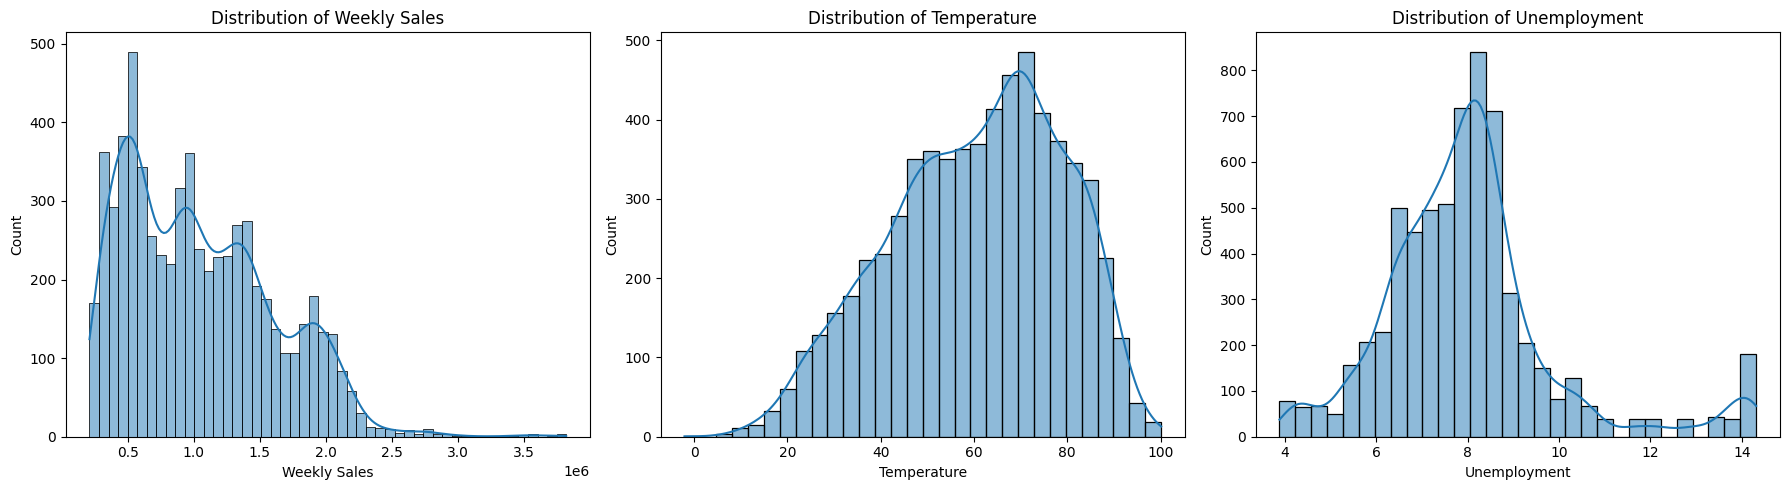

In [ ]:
# histogram + KDE: weekly sales
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df['weekly_sales'], bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Weekly Sales')
axes[0].set_xlabel('Weekly Sales')

sns.histplot(df['temperature'], bins=30, kde=True, ax=axes[1])
axes[1].set_title('Distribution of Temperature')
axes[1].set_xlabel('Temperature')

sns.histplot(df['unemployment'], bins=30, kde=True, ax=axes[2])
axes[2].set_title('Distribution of Unemployment')
axes[2].set_xlabel('Unemployment')

plt.tight_layout()
plt.show()

- **Histogram + KDE:** Weekly Sales
Weekly sales are right-skewed. Most weeks fall between about 0.3M and 2.0M, with a long thin tail up to about 3.8M. The curve has several peaks (around 0.5M, 1.0M, 1.4M and 1.9M). This probably happens because stores differ a lot in size, so the data is a mix of small and big stores.
- **Histogram + KDE: Temperature**
Temperature is roughly bell-shaped, with a slight lean to the left. Most weeks are between 40°F and 85°F and the peak is around 70°F. There are very few extreme cold or hot weeks.
- **Histogram + KDE: Unemployment**
Unemployment is centered around 8%, and most values fall between 6% and 9%. There is a small separate cluster at about 14%, which comes from a few stores in high-unemployment areas. These are the outliers we kept in Task 1.

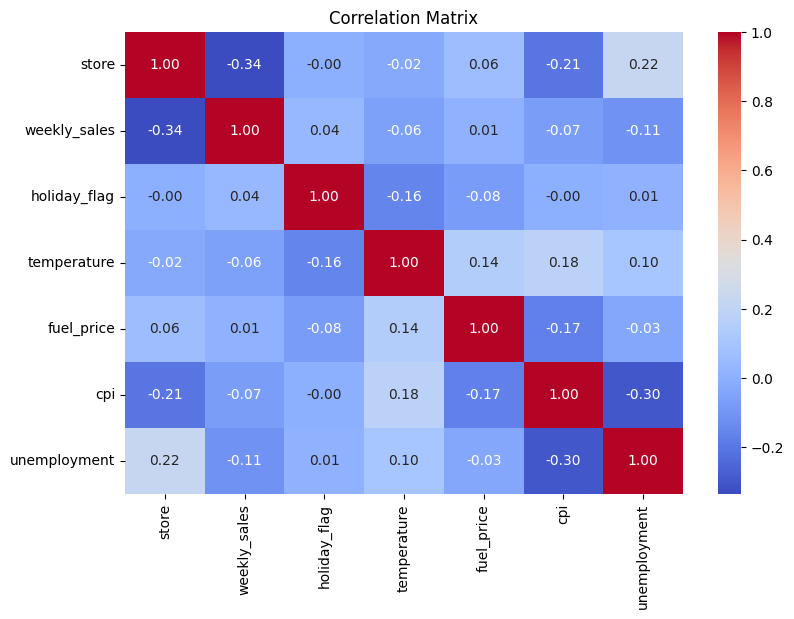

In [ ]:
#correlation heatmap
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

All the correlations with weekly sales are weak: unemployment (-0.11), CPI (-0.07), temperature (-0.06), holiday flag (0.04) and fuel price (0.01). So no single economic factor explains sales on its own. The store column shows -0.34, but store is just an ID number, so that value isn't meaningful. It only tells us that stores differ a lot. CPI and unemployment are moderately negatively correlated (-0.30).

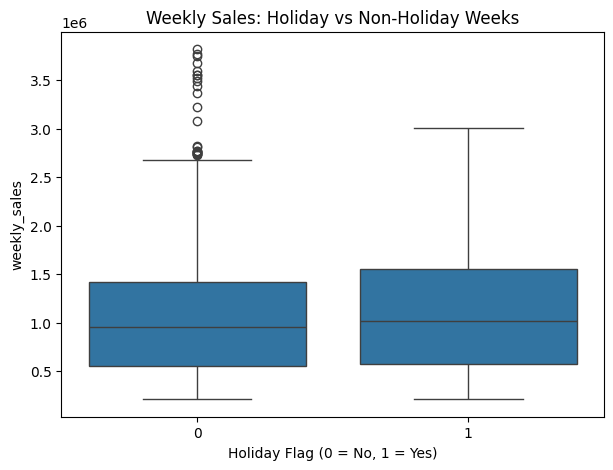

In [ ]:
#Box plot: Holiday vs Non-Holiday
plt.figure(figsize=(7, 5))
sns.boxplot(x='holiday_flag', y='weekly_sales', data=df)
plt.title('Weekly Sales: Holiday vs Non-Holiday Weeks')
plt.xlabel('Holiday Flag (0 = No, 1 = Yes)')
plt.show()

Holiday weeks have a slightly higher median and box than non-holiday weeks, but the difference is small. Most of the highest sales (above 3M) are in the non-holiday group. That's likely because the pre-Christmas week isn't flagged as a holiday in this dataset, so the flag misses the biggest sales week.

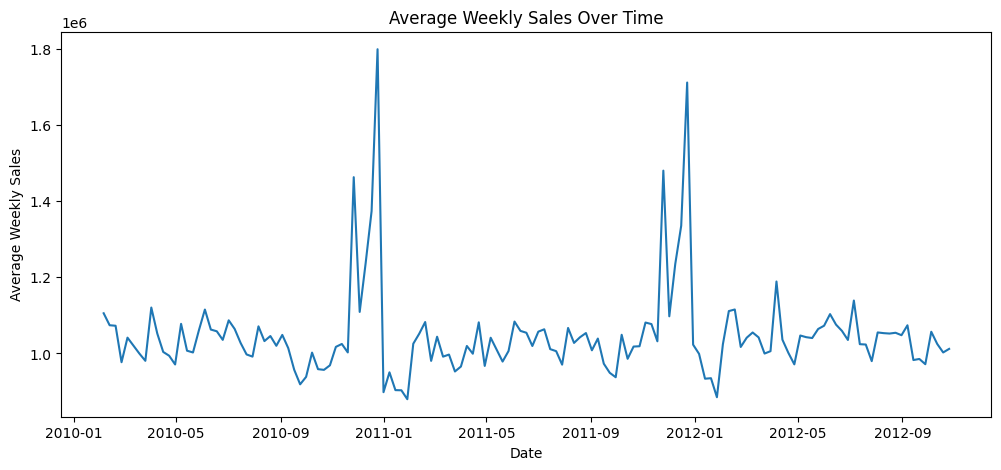

In [ ]:
#line chart: average weekly sales over time
weekly_avg = df.groupby('date')['weekly_sales'].mean()

plt.figure(figsize=(12, 5))
plt.plot(weekly_avg.index, weekly_avg.values)
plt.title('Average Weekly Sales Over Time')
plt.xlabel('Date')
plt.ylabel('Average Weekly Sales')
plt.show()

Sales stay around 1.0M for most of the year, with clear seasonal spikes every year. One peak is around Thanksgiving (late Nov), and the largest is just before Christmas (late Dec), reaching about 1.8M. Sales drop to their lowest right after (Jan). There are also small bumps around April.

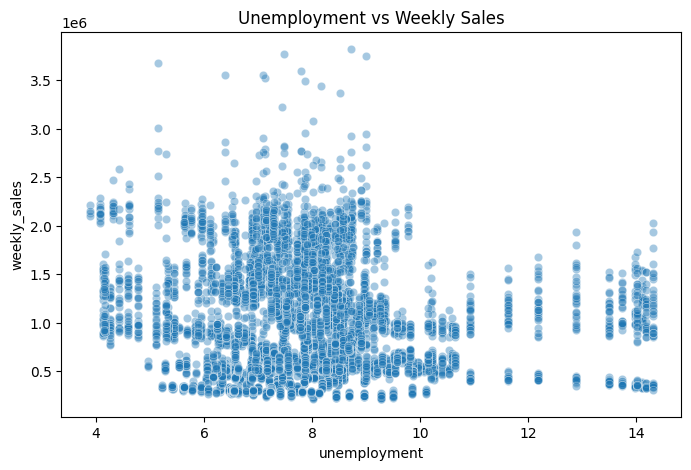

In [ ]:
#Scatter plot: Unemployment vs Weekly Sales
plt.figure(figsize=(8, 5))
sns.scatterplot(x='unemployment', y='weekly_sales', data=df, alpha=0.4)
plt.title('Unemployment vs Weekly Sales')
plt.show()

Higher unemployment goes with lower sales. Above about 10% unemployment, almost no weeks go over 2.0M, while the highest sales happen at 6-9%. The vertical stripes happen because each store has almost the same unemployment value every week. The relationship is weak, so unemployment isn't the only factor.

store
20    2.107677e+06
4     2.094713e+06
14    2.020978e+06
13    2.003620e+06
2     1.925751e+06
Name: weekly_sales, dtype: float64
store
38    385731.653287
36    373511.992797
5     318011.810490
44    302748.866014
33    259861.692028
Name: weekly_sales, dtype: float64
High-unemployment stores avg sales: 906,085
Low-unemployment stores avg sales: 1,482,902


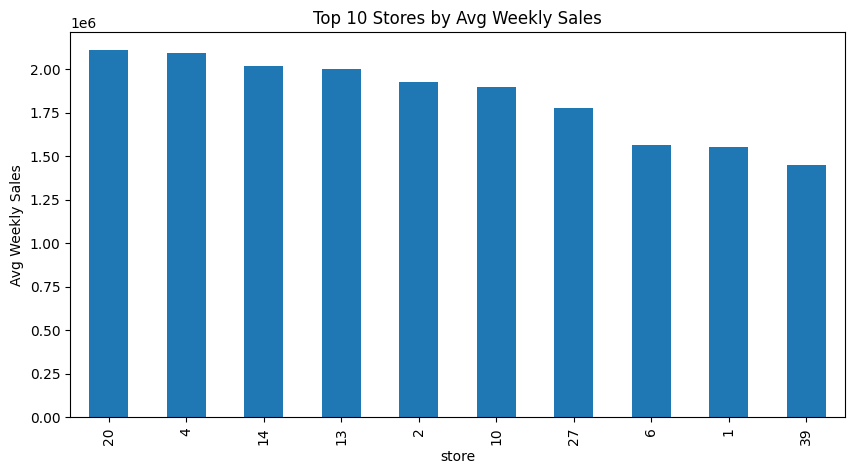

In [ ]:
# group-by analysis: Stores
# Average sales per store: top 5 and bottom 5
store_avg = df.groupby('store')['weekly_sales'].mean().sort_values(ascending=False)
print(store_avg.head(5))
print(store_avg.tail(5))

# Your hypothesis: high vs low unemployment stores
high = df[df['store'].isin([12, 28, 38])]['weekly_sales'].mean()
low = df[df['store'].isin([4, 23, 40])]['weekly_sales'].mean()
print(f'High-unemployment stores avg sales: {high:,.0f}')
print(f'Low-unemployment stores avg sales: {low:,.0f}')

# Bar chart of the top 10 stores
store_avg.head(10).plot(kind='bar', figsize=(10, 5), title='Top 10 Stores by Avg Weekly Sales')
plt.ylabel('Avg Weekly Sales')
plt.show()

Store 20 is the best (about 2.1M average weekly sales), followed by stores 4, 14, 13 and 2. The weakest are stores 33, 44, 5, 36 and 38 (about 260K-386K). The top store sells about 8 times more than the bottom one. Stores in high-unemployment areas (12, 28, 38) averaged 906,085, while those in low-unemployment areas (4, 23, 40) averaged 1,482,902. That's about 39% lower, which supports your hypothesis.

## Key Insights

**1. Sales are strongly seasonal.**
Weekly sales stay around 1.0M for most of the year but spike around Thanksgiving (late Nov) and peak just before Christmas (late Dec), reaching about 1.8M. The holiday flag in the dataset does not capture the pre-Christmas week, which is the biggest sales week.
- *Recommendation:* Plan inventory and staffing ahead of late Nov and late Dec every year.

**2. The store matters more than any economic factor.**
Store 20 averages about 2.1M per week, while store 33 averages about 260K, roughly 8 times less. Temperature, fuel price and CPI show almost no correlation with sales (all below 0.1 in absolute value).
- *Recommendation:* Study what top stores like 20 and 4 do differently and apply it to weaker stores.

**3. High unemployment is linked to lower sales.**
Stores in high-unemployment areas (12, 28, 38) averaged 906,085 per week, compared with 1,482,902 for stores in low-unemployment areas (4, 23, 40). That is about 39% lower. This comparison uses only 3 stores per group and store size may also play a part, so it shows a link, not proof of cause.
- *Recommendation:* Use targeted promotions and lower-priced products in high-unemployment areas.

---

## Conclusion

Store and season explain most of the variation in Walmart's weekly sales, while weather and fuel price matter very little. Unemployment has a weak negative link with sales, but it is mixed up with store differences.
